# 02 – DAG didaktik (Detyra E)
Projekti 06 • Java 2 • Roli D (Gerald Paja)

Shembull **neutral**, i ndarë nga literatura aSAH (sipas seksionit 10.6 të detyrës):
*Sezoni i verës → Temperatura e lartë → Shitje akulloresh* dhe *Temperatura e lartë → Vizita në plazh*.

> Shigjetat janë **supozime** të modeluesit, jo fakte të nxjerra nga të dhënat. Mungesa e cikleve është kusht
> teknik i një DAG-u, jo provë shkakësie. Ky nuk është DoWhy dhe nuk përdoret për relacione klinike.

In [1]:
from pathlib import Path
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

G = nx.DiGraph()
supozimet = [
    ("Sezoni i verës", "Temperatura e lartë", "S1: vera sjell ditë më të nxehta"),
    ("Temperatura e lartë", "Shitje akulloresh", "S2: kur është nxehtë blihen më shumë akullore"),
    ("Temperatura e lartë", "Vizita në plazh", "S3: kur është nxehtë shkohet më shumë në plazh"),
]
for a, b, s in supozimet:
    G.add_edge(a, b, supozim=s)

print("Nyje:", list(G.nodes))
print("Shigjeta:")
for a, b, d in G.edges(data=True):
    print(f"   {a} → {b}   [{d['supozim']}]")
print("\nA është DAG (pa cikle)?", nx.is_directed_acyclic_graph(G))
print("Rendi topologjik:", " → ".join(nx.topological_sort(G)))

Nyje: ['Sezoni i verës', 'Temperatura e lartë', 'Shitje akulloresh', 'Vizita në plazh']
Shigjeta:
   Sezoni i verës → Temperatura e lartë   [S1: vera sjell ditë më të nxehta]
   Temperatura e lartë → Shitje akulloresh   [S2: kur është nxehtë blihen më shumë akullore]
   Temperatura e lartë → Vizita në plazh   [S3: kur është nxehtë shkohet më shumë në plazh]

A është DAG (pa cikle)? True
Rendi topologjik: Sezoni i verës → Temperatura e lartë → Shitje akulloresh → Vizita në plazh


## 1. Roja kundër cikleve
Çdo shigjetë e re shtohet vetëm nëse grafi mbetet pa cikle (si do të bëjë paneli i javës 8).

In [2]:
def shto_shigjete(G, a, b, supozim):
    G.add_edge(a, b, supozim=supozim)
    if not nx.is_directed_acyclic_graph(G):
        cikli = nx.find_cycle(G)
        G.remove_edge(a, b)
        print(f"REFUZUAR: {a} → {b} krijon ciklin {cikli}")
        return False
    print(f"PRANUAR: {a} → {b}")
    return True

shto_shigjete(G, "Shitje akulloresh", "Temperatura e lartë", "supozim i gabuar: akullorja ngroh motin")
shto_shigjete(G, "Shitje akulloresh", "Vizita në plazh", "supozim i padokumentuar")
G.remove_edge("Shitje akulloresh", "Vizita në plazh")  # e heqim: nuk ka arsyetim për këtë shigjetë
print("Pas rishikimit, DAG:", nx.is_directed_acyclic_graph(G), "| shigjeta:", G.number_of_edges())

REFUZUAR: Shitje akulloresh → Temperatura e lartë krijon ciklin [('Temperatura e lartë', 'Shitje akulloresh'), ('Shitje akulloresh', 'Temperatura e lartë')]
PRANUAR: Shitje akulloresh → Vizita në plazh
Pas rishikimit, DAG: True | shigjeta: 3


## 2. Vizatimi i grafit

Figura u ruajt: results/02_DAG_Didaktik.png


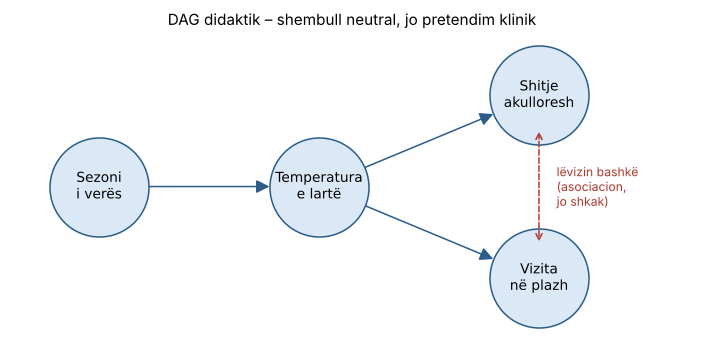

In [3]:
pos = {"Sezoni i verës": (0, 1), "Temperatura e lartë": (1, 1),
       "Shitje akulloresh": (2, 1.6), "Vizita në plazh": (2, 0.4)}
fig, ax = plt.subplots(figsize=(8, 3.6))
nx.draw_networkx_nodes(G, pos, node_color="#dbe9f6", edgecolors="#2b5d8a", node_size=4200, ax=ax)
nx.draw_networkx_labels(G, pos, labels={n: n.replace(" ", "\n", 1) for n in G}, font_size=9, ax=ax)
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=18, node_size=4200, edge_color="#2b5d8a", ax=ax)
ax.annotate("", xy=(2, 0.62), xytext=(2, 1.38),
            arrowprops=dict(arrowstyle="<->", ls="--", color="#b03a2e"))
ax.text(2.08, 1.0, "lëvizin bashkë\n(asociacion,\njo shkak)", color="#b03a2e", fontsize=8, va="center")
ax.set_title("DAG didaktik – shembull neutral, jo pretendim klinik", fontsize=10)
ax.set_xlim(-0.4, 2.7); ax.set_ylim(0, 2); ax.axis("off")
fig.savefig(Path("..") / "results/02_DAG_Didaktik.png", dpi=150, bbox_inches="tight")
print("Figura u ruajt: results/02_DAG_Didaktik.png")

## 3. Pse asociacion ≠ shkakësi (simulim i vogël me të dhëna të sajuara)
Krijojmë të dhëna ku **akullorja nuk ndikon fare** te plazhi; të dyja varen vetëm nga temperatura.
Megjithatë ato dalin të korreluara. Kur krahasojmë ditë me temperaturë të ngjashme, lidhja pothuajse zhduket.
Të dhënat janë sintetike dhe shërbejnë vetëm për ilustrim.

In [4]:
rng = np.random.default_rng(42)
n = 2000
temperatura = rng.normal(25, 6, n)
akullore = 2.0 * temperatura + rng.normal(0, 8, n)   # varet vetëm nga temperatura
plazh = 1.5 * temperatura + rng.normal(0, 8, n)      # varet vetëm nga temperatura

r_total = np.corrcoef(akullore, plazh)[0, 1]
mask = (temperatura > 24) & (temperatura < 26)        # "kontrollojmë" confounder-in
r_strata = np.corrcoef(akullore[mask], plazh[mask])[0, 1]
print(f"Korrelacioni akullore–plazh (të gjitha ditët):        r = {r_total:.2f}")
print(f"Korrelacioni brenda ditëve me temperaturë 24–26 °C:  r = {r_strata:.2f}")
print("\nPërfundimi: lidhja vjen nga confounder-i (temperatura), jo nga akullorja.")

Korrelacioni akullore–plazh (të gjitha ditët):        r = 0.64
Korrelacioni brenda ditëve me temperaturë 24–26 °C:  r = 0.10

Përfundimi: lidhja vjen nga confounder-i (temperatura), jo nga akullorja.


## 4. Supozimet dhe kufijtë e interpretimit
| Kodi | Supozimi | Si mund të jetë i gabuar |
|---|---|---|
| S1 | Sezoni → Temperatura | ka verë me ditë të freskëta; edhe gjeografia ndikon |
| S2 | Temperatura → Akullore | çmimet, festat ose turizmi mund të ndikojnë po aq |
| S3 | Temperatura → Plazh | fundjava dhe pushimet janë faktorë të tjerë që mungojnë në graf |

- Grafi paraqet **hipoteza** të deklaruara. Nuk u vlerësua asnjë efekt shkakësor (DoWhy vjen në javët 9–10).
- Në projekt, çdo shigjetë mbi literaturën aSAH do të kërkojë pasazh burimor dhe **rishikim njerëzor** (java 8).